<a href="https://colab.research.google.com/github/jelvalojel-glitch/ML_task_04/blob/main/Task04.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

uploaded = files.upload()
filename = next(iter(uploaded))

df = pd.read_csv(filename)

print("Размер датасета:", df.shape)
print("\nПервые 5 строк:")
display(df.head())

print("\nТипы данных:")
print(df.dtypes)

print("\nКоличество пропусков:")
print(df.isnull().sum())

Saving machine-readable-business-employment-data-june-2026-quarter .csv to machine-readable-business-employment-data-june-2026-quarter .csv
Размер датасета: (26446, 14)

Первые 5 строк:


,Series_reference,Period,Data_value,Suppressed,STATUS,UNITS,Magnitude,Subject,Group,Series_title_1,Series_title_2,Series_title_3,Series_title_4,Series_title_5
0,BDCQ.SEA1AA,2011.06,80078.0,NaN,F,Number,0,Business Data Collection - BDC,Industry by employment variable,Filled jobs,"Agriculture, Forestry and Fishing",Actual,NaN,NaN
1,BDCQ.SEA1AA,2011.09,78324.0,NaN,F,Number,0,Business Data Collection - BDC,Industry by employment variable,Filled jobs,"Agriculture, Forestry and Fishing",Actual,NaN,NaN
2,BDCQ.SEA1AA,2011.12,85850.0,NaN,F,Number,0,Business Data Collection - BDC,Industry by employment variable,Filled jobs,"Agriculture, Forestry and Fishing",Actual,NaN,NaN
3,BDCQ.SEA1AA,2012.03,90743.0,NaN,F,Number,0,Business Data Collection - BDC,Industry by employment variable,Filled jobs,"Agriculture, Forestry and Fishing",Actual,NaN,NaN
4,BDCQ.SEA1AA,2012.06,81780.0,NaN,F,Number,0,Business Data Collection - BDC,Industry by employment variable,Filled jobs,"Agriculture, Forestry and Fishing",Actual,NaN,NaN



Типы данных:
Series_reference     object
Period              float64
Data_value          float64
Suppressed           object
STATUS               object
UNITS                object
Magnitude             int64
Subject              object
Group                object
Series_title_1       object
Series_title_2       object
Series_title_3       object
Series_title_4      float64
Series_title_5      float64
dtype: object

Количество пропусков:
Series_reference        0
Period                  0
Data_value           2839
Suppressed          23607
STATUS                  0
UNITS                   0
Magnitude               0
Subject                 0
Group                   0
Series_title_1          0
Series_title_2          0
Series_title_3          0
Series_title_4      26446
Series_title_5      26446
dtype: int64


In [3]:
# Посмотреть названия всех столбцов
print(df.columns.tolist())

['Series_reference', 'Period', 'Data_value', 'Suppressed', 'STATUS', 'UNITS', 'Magnitude', 'Subject', 'Group', 'Series_title_1', 'Series_title_2', 'Series_title_3', 'Series_title_4', 'Series_title_5']


In [5]:
# ЗАМЕНИ на реальное название целевого столбца
target = "Data_value"

if target not in df.columns:
    raise ValueError(f"Столбец {target!r} не найден!")

if not pd.api.types.is_numeric_dtype(df[target]):
    raise ValueError("Для линейной регрессии целевая переменная должна быть числовой.")

# Удаляем строки, в которых неизвестно целевое значение
data = df.dropna(subset=[target]).copy()

# Берём все доступные числовые признаки, кроме целевого
numeric_features = data.select_dtypes(include=np.number).columns.tolist()
numeric_features = [
    col for col in numeric_features if col != target
]

if not numeric_features:
    raise ValueError("В датасете нет числовых признаков для обучения.")

X = data[numeric_features]
y = data[target]

print("Целевая переменная:", target)
print("Количество числовых признаков:", len(numeric_features))
print("Признаки:", numeric_features)
print("Количество строк:", len(data))

Целевая переменная: Data_value
Количество числовых признаков: 4
Признаки: ['Period', 'Magnitude', 'Series_title_4', 'Series_title_5']
Количество строк: 23607


In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Обучающая выборка:", X_train.shape)
print("Тестовая выборка:", X_test.shape)

Обучающая выборка: (18885, 4)
Тестовая выборка: (4722, 4)


In [7]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Базовая модель использует все числовые признаки
baseline_model = make_pipeline(
    SimpleImputer(strategy="median"),
    LinearRegression()
)

baseline_model.fit(X_train, y_train)

y_pred_baseline = baseline_model.predict(X_test)


def calculate_metrics(y_true, y_pred):
    return {
        "R2": r2_score(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred))
    }


baseline_metrics = calculate_metrics(y_test, y_pred_baseline)

print("Метрики базовой модели:")
for metric, value in baseline_metrics.items():
    print(f"{metric}: {value:.4f}")

Метрики базовой модели:
R2: 0.0469
MAE: 85822.4373
RMSE: 229134.2077


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Series_title_4' 'Series_title_5']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Series_title_4' 'Series_title_5']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


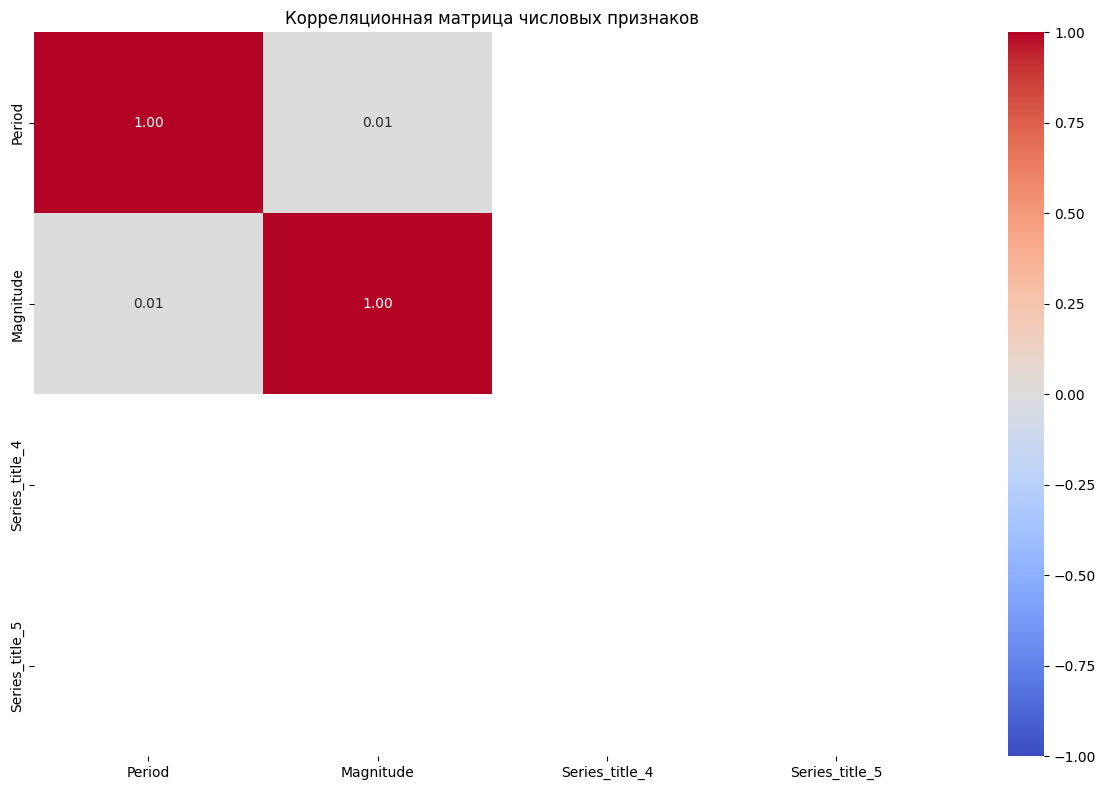

In [8]:
correlation_matrix = X_train.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Корреляционная матрица числовых признаков")
plt.tight_layout()
plt.show()

In [9]:
threshold = 0.85

corr_pairs = []

for i in range(len(correlation_matrix.columns)):
    for j in range(i + 1, len(correlation_matrix.columns)):
        corr_value = correlation_matrix.iloc[i, j]

        if abs(corr_value) > threshold:
            corr_pairs.append({
                "Признак 1": correlation_matrix.columns[i],
                "Признак 2": correlation_matrix.columns[j],
                "Корреляция": corr_value
            })

corr_pairs_df = pd.DataFrame(
    corr_pairs,
    columns=["Признак 1", "Признак 2", "Корреляция"]
)

if corr_pairs_df.empty:
    print("Пар с абсолютной корреляцией выше", threshold, "не найдено.")
else:
    display(
        corr_pairs_df.sort_values(
            "Корреляция",
            key=lambda s: s.abs(),
            ascending=False
        )
    )

Пар с абсолютной корреляцией выше 0.85 не найдено.


In [11]:
%pip -q install statsmodels

In [13]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.impute import SimpleImputer

# Исключаем столбцы, в которых абсолютно все значения пропущены,
# так как их невозможно заполнить с помощью SimpleImputer
X_train_valid = X_train.dropna(how="all", axis=1)

# Заполняем пропуски в оставшихся столбцах
X_vif = pd.DataFrame(
    SimpleImputer(strategy="median").fit_transform(X_train_valid),
    columns=X_train_valid.columns,
    index=X_train_valid.index
)

# Убираем константные столбцы, если они есть
X_vif = X_vif.loc[:, X_vif.nunique() > 1]

# Стандартизация помогает улучшить численную устойчивость расчёта
X_vif_scaled = (
    (X_vif - X_vif.mean()) /
    X_vif.std().replace(0, 1)
)

vif_df = pd.DataFrame({
    "Признак": X_vif_scaled.columns,
    "VIF": [
        variance_inflation_factor(
            X_vif_scaled.to_numpy(),
            i
        )
        for i in range(X_vif_scaled.shape[1])
    ]
})

display(vif_df.sort_values("VIF", ascending=False))

,Признак,VIF
1,Magnitude,1.000033
0,Period,1.000033


In [14]:
selected_features = []
removed_features = []

for feature in X_train.columns:
    highly_correlated = False

    for selected in selected_features:
        corr_value = X_train[feature].corr(X_train[selected])

        if pd.notna(corr_value) and abs(corr_value) > threshold:
            highly_correlated = True
            removed_features.append(feature)
            break

    if not highly_correlated:
        selected_features.append(feature)

print("Оставленные признаки:", selected_features)
print("Исключённые признаки:", removed_features)

Оставленные признаки: ['Period', 'Magnitude', 'Series_title_4', 'Series_title_5']
Исключённые признаки: []


In [15]:
reduced_model = make_pipeline(
    SimpleImputer(strategy="median"),
    LinearRegression()
)

reduced_model.fit(X_train[selected_features], y_train)

y_pred_reduced = reduced_model.predict(X_test[selected_features])

reduced_metrics = calculate_metrics(y_test, y_pred_reduced)

print("Метрики сокращённой модели:")
for metric, value in reduced_metrics.items():
    print(f"{metric}: {value:.4f}")

Метрики сокращённой модели:
R2: 0.0469
MAE: 85822.4373
RMSE: 229134.2077


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Series_title_4' 'Series_title_5']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Series_title_4' 'Series_title_5']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


In [16]:
reduced_model = make_pipeline(
    SimpleImputer(strategy="median"),
    LinearRegression()
)

reduced_model.fit(X_train[selected_features], y_train)

y_pred_reduced = reduced_model.predict(X_test[selected_features])

reduced_metrics = calculate_metrics(y_test, y_pred_reduced)

print("Метрики сокращённой модели:")
for metric, value in reduced_metrics.items():
    print(f"{metric}: {value:.4f}")

Метрики сокращённой модели:
R2: 0.0469
MAE: 85822.4373
RMSE: 229134.2077


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Series_title_4' 'Series_title_5']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Series_title_4' 'Series_title_5']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


In [17]:
comparison = pd.DataFrame(
    [baseline_metrics, reduced_metrics],
    index=["Базовая: все признаки", "Сокращённая: меньше признаков"]
)

comparison["Количество признаков"] = [
    len(numeric_features),
    len(selected_features)
]

display(comparison.round(4))

,R2,MAE,RMSE,Количество признаков
Базовая: все признаки,0.0469,85822.4373,229134.2077,4
Сокращённая: меньше признаков,0.0469,85822.4373,229134.2077,4


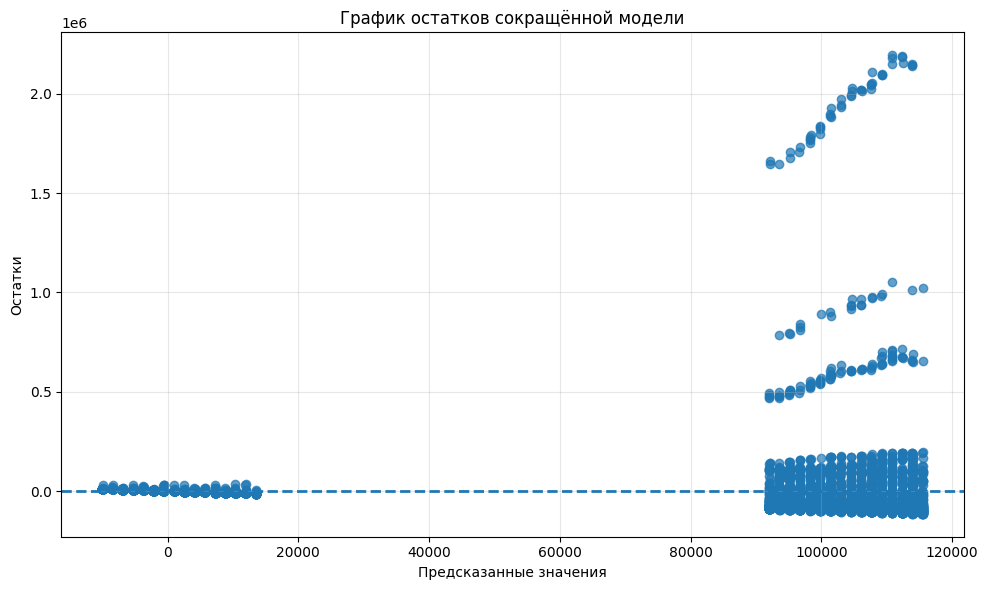

In [18]:
residuals = y_test - y_pred_reduced

plt.figure(figsize=(10, 6))

plt.scatter(
    y_pred_reduced,
    residuals,
    alpha=0.7
)

plt.axhline(
    y=0,
    linestyle="--",
    linewidth=2
)

plt.xlabel("Предсказанные значения")
plt.ylabel("Остатки")
plt.title("График остатков сокращённой модели")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()